In [17]:
import pandas as pd

In [31]:
df = pd.read_excel(r'C:\Backup_D\Dolanan_VScode\irlo.xlsx', sheet_name=4)
df.head()

,Date,Order ID,Customer ID,Weight,Piece,Piece Type,Service Speed,Service,Sales,Region
0,2025-09-01,1001,INE729,0.96,NaN,NaN,Reguler,Complete Wash,24.00,GJM
1,2025-09-01,1002,PER783,3.38,NaN,NaN,Reguler,Complete Wash,27.04,GJM
2,2025-09-01,1002,PER783,0.00,Small Bed Sheet Set,Bed Sheet,Piece,Piece,15.00,GJM
3,2025-09-01,1003,PUR183,4.49,NaN,NaN,Reguler,Complete Wash,35.92,GJM
4,2025-09-01,1003,PUR183,0.00,Small Bed Sheet Set,Bed Sheet,Piece,Piece,15.00,GJM


In [20]:
df2 = df[['Date', 'Customer ID']].copy()
df2.head()

,Date,Customer ID
0,2025-09-01,INE729
1,2025-09-01,PER783
2,2025-09-01,PER783
3,2025-09-01,PUR183
4,2025-09-01,PUR183


In [21]:
df2['datetime'] = pd.to_datetime(df['Date'], utc=True)
df2['month'] = df2['datetime'].dt.month
df2['year'] = df2['datetime'].dt.year

df2.head()

,Date,Customer ID,datetime,month,year
0,2025-09-01,INE729,2025-09-01 00:00:00+00:00,9,2025
1,2025-09-01,PER783,2025-09-01 00:00:00+00:00,9,2025
2,2025-09-01,PER783,2025-09-01 00:00:00+00:00,9,2025
3,2025-09-01,PUR183,2025-09-01 00:00:00+00:00,9,2025
4,2025-09-01,PUR183,2025-09-01 00:00:00+00:00,9,2025


Create Cohort

In [22]:
df2['cohort'] = (
    df2.apply(lambda row: (row['year'] * 100)
    +
    (row['month']), axis=1)
)

df2.head()

,Date,Customer ID,datetime,month,year,cohort
0,2025-09-01,INE729,2025-09-01 00:00:00+00:00,9,2025,202509
1,2025-09-01,PER783,2025-09-01 00:00:00+00:00,9,2025,202509
2,2025-09-01,PER783,2025-09-01 00:00:00+00:00,9,2025,202509
3,2025-09-01,PUR183,2025-09-01 00:00:00+00:00,9,2025,202509
4,2025-09-01,PUR183,2025-09-01 00:00:00+00:00,9,2025,202509


In [24]:
cohorts = (
    df2
    .groupby('Customer ID')['cohort']
    .min()
    .reset_index()
)
cohorts.columns = ['Customer ID', 'first_cohort']

df2 = df2.merge(
    cohorts,
    on='Customer ID',
    how='left'
)

df2.head()

,Date,Customer ID,datetime,month,year,cohort,first_cohort
0,2025-09-01,INE729,2025-09-01 00:00:00+00:00,9,2025,202509,202509
1,2025-09-01,PER783,2025-09-01 00:00:00+00:00,9,2025,202509,202509
2,2025-09-01,PER783,2025-09-01 00:00:00+00:00,9,2025,202509,202509
3,2025-09-01,PUR183,2025-09-01 00:00:00+00:00,9,2025,202509,202509
4,2025-09-01,PUR183,2025-09-01 00:00:00+00:00,9,2025,202509,202509


In [25]:
headers = sorted(df2['cohort'].dropna().unique().tolist())
df2['cohort_distance'] = df2.apply(
    lambda row: (headers.index(row['cohort']) - headers.index(row['first_cohort']))
    if pd.notna(row['first_cohort']) and pd.notna(row['cohort'])
    else None,
    axis=1
)
df2.tail()

,Date,Customer ID,datetime,month,year,cohort,first_cohort,cohort_distance
9333,2026-02-28,JAV129,2026-02-28 00:00:00+00:00,2,2026,202602,202509,5
9334,2026-02-28,ANI982,2026-02-28 00:00:00+00:00,2,2026,202602,202509,5
9335,2026-02-28,DHA526,2026-02-28 00:00:00+00:00,2,2026,202602,202509,5
9336,2026-02-28,SHA685,2026-02-28 00:00:00+00:00,2,2026,202602,202509,5
9337,2026-02-28,RAH899,2026-02-28 00:00:00+00:00,2,2026,202602,202510,4


In [27]:
cohort_pv = pd.pivot_table(
    df2,
    index='first_cohort',
    columns='cohort_distance',
    values='Customer ID',
    aggfunc='nunique'
)
cohort_pv

cohort_distance,0,1,2,3,4,5
first_cohort,,,,,,
202509,301.0,283.0,267.0,265.0,231.0,265.0
202510,51.0,23.0,34.0,32.0,37.0,NaN
202511,53.0,36.0,31.0,34.0,NaN,NaN
202512,29.0,15.0,20.0,NaN,NaN,NaN
202601,8.0,7.0,NaN,NaN,NaN,NaN
202602,7.0,NaN,NaN,NaN,NaN,NaN


In [28]:
cohort_pv = cohort_pv.div(cohort_pv[0], axis=0)
cohort_pv

cohort_distance,0,1,2,3,4,5
first_cohort,,,,,,
202509,1.0,0.940199,0.887043,0.880399,0.767442,0.880399
202510,1.0,0.450980,0.666667,0.627451,0.725490,NaN
202511,1.0,0.679245,0.584906,0.641509,NaN,NaN
202512,1.0,0.517241,0.689655,NaN,NaN,NaN
202601,1.0,0.875000,NaN,NaN,NaN,NaN
202602,1.0,NaN,NaN,NaN,NaN,NaN


Visualization

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

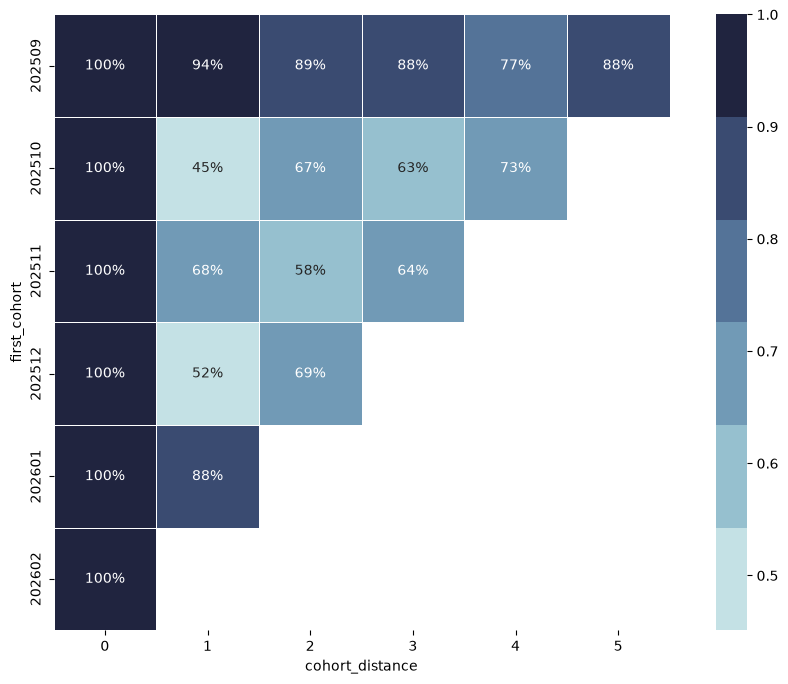

In [30]:
fig_dims = (12,8)
fig, ax = plt.subplots(figsize=fig_dims)
sns.heatmap(
    cohort_pv,
    annot=True,
    fmt='.0%',
    mask=cohort_pv.isnull(),
    ax=ax,
    square=True,
    linewidths=.5,
    cmap=sns.cubehelix_palette(rot=-.2)
)

plt.show()